
# Lab 8: Monte Carlo Markov Chain (MCMC)

**Exercise 1**:
 
* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [1]:
import numpy as np
from scipy import integrate
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Función de clase
def monte_carlo_integration(func, a, b, num_samples=1000):
    integral_sum = 0
    for _ in range(num_samples):
        x = np.random.uniform(a, b)
        integral_sum += func(x)
    return (b - a) * (integral_sum / num_samples)

# Generalización a 2D: Volumen
def monte_carlo_2d(func, ax, bx, ay, by, num_samples=1000):
    x = np.random.uniform(ax, bx, num_samples)
    y = np.random.uniform(ay, by, num_samples)
    return (bx - ax) * (by - ay) * np.mean(func(x, y))

N = 100000

# PRimera integral: f(x) = sqrt(x) en [0,4]
f1 = lambda x: x**0.5
mc1  = monte_carlo_integration(f1, 0, 4, N)
exa1 = 16/3 # valor exacto obtenido de wolfram alpha
qd1  = integrate.quad(f1, 0, 4)[0]
print(f"1) MC={mc1:.5f}  quad={qd1:.5f}  analítico={exa1:.5f}  "
      f"error abs={abs(mc1-exa1):.5f}  rel={abs(mc1-exa1)/exa1*100:.4f}%")

# SEgunda integral: f(x,y) = x*y^2 en [0,2]x[0,1]
f2 = lambda x, y: x*y**2
mc2  = monte_carlo_2d(f2, 0, 2, 0, 1, N)
exa2 = 2/3 # valor exacto obtenido de wolfram alpha
qd2  = integrate.dblquad(lambda y, x: x*y**2, 0, 2, 0, 1)[0]
print(f"2) MC={mc2:.5f}  dblquad={qd2:.5f}  analítico={exa2:.5f}  "
      f"error abs={abs(mc2-exa2):.5f}  rel={abs(mc2-exa2)/exa2*100:.4f}%\n")

# Análisis de convergencia
for n in [100, 1000, 10000, 100000]:
    print(n, round(monte_carlo_integration(f1,0,4,n),4), round(monte_carlo_2d(f2,0,2,0,1,n),4))

1) MC=5.32736  quad=5.33333  analítico=5.33333  error abs=0.00597  rel=0.1119%
2) MC=0.66957  dblquad=0.66667  analítico=0.66667  error abs=0.00290  rel=0.4354%

100 5.1329 0.5537
1000 5.2656 0.7173
10000 5.3462 0.6692
100000 5.3358 0.6684


**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

In [3]:
# Inicialización de la red de espines
n = 10
N = n * n
red = np.random.choice([-1, 1], size=(n, n))
energy = np.zeros((n, n))
x = []
C = 0.6717098224  # magnetón de Bohr / k_B (K/T)
J = 1.0  # J/k_B en Kelvin

# Por cada temperatura y campo magnético, se realiza la simulación de Monte Carlo
# añadiendo respecto al código de clase la interacción de los primeros vecinos y la magnetización promedio por paso medido
for T in [5, 10, 15]:
    for H in np.arange(-30, 31, 0.5):
        Mag = 0
        red = np.random.choice([-1, 1], size=(n, n)) # reiniciar la red para cada temperatura y campo 
        # esto para evitar que la magnetización promedio se vea afectada por la configuración inicial de la red

        # Pasos de termalización y medición
        MC_eq = 1000
        MC_med = 2000
        MC = MC_eq + MC_med

        for m in range(MC):

            # Visitar espines de la red
            for i in range(n):
                for j in range(n):

                    # Energía incluyendo primeros vecinos
                    vecinos = (red[(i+1) % n, j] + red[(i-1) % n, j] +
                               red[i, (j+1) % n] + red[i, (j-1) % n])

                    # Condiciones periódicas de frontera
                    energy[i, j] = -red[i, j] * (J * vecinos + C * H)
                    stemp = -red[i, j]

                    # Energía del espín invertido
                    energytemp = -stemp * (J * vecinos + C * H)

                    deltae = energytemp - energy[i, j]

                    # Algoritmo de Metropolis
                    if deltae <= 0:
                        red[i, j] = stemp

                    else:
                        b = np.exp(-deltae / T)
                        r = np.random.rand()

                        if r < b:
                            red[i, j] = stemp

            # magnetización después de termalización
            if m >= MC_eq:
                Mag += np.sum(red) / N

        # Promedio de magnetización por paso medido
        Magpro = Mag / MC_med

        x.append([T, H, Magpro])

x = np.asarray(x)

xd = pd.DataFrame(x, columns=['T', 'H', 'Magnetization'])

# Dataframe para cada temperatura
T1 = xd[xd['T'] == 5]
T2 = xd[xd['T'] == 10]
T3 = xd[xd['T'] == 15]

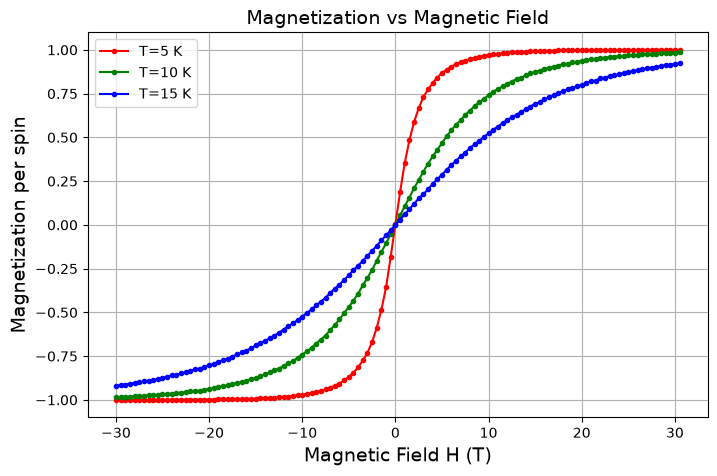

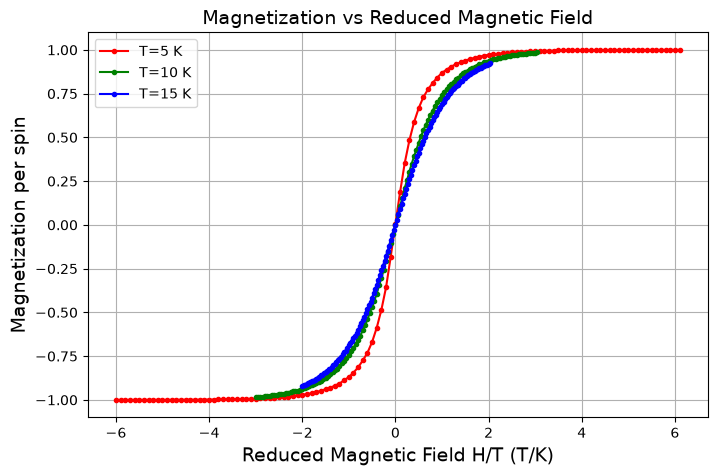

In [ ]:
# Gráfica de magnetización vs campo magnético: código de clase

plt.figure(figsize=(8, 5))

plt.plot(T1['H'], T1['Magnetization'], 'r.-', label='T=5 K')
plt.plot(T2['H'], T2['Magnetization'], 'g.-', label='T=10 K')
plt.plot(T3['H'], T3['Magnetization'], 'b.-', label='T=15 K')

plt.xlabel('Magnetic Field H (T)', size=14)
plt.ylabel('Magnetization per spin', size=14)
plt.title('Magnetization vs Magnetic Field', size=14)

plt.legend(loc='best')
plt.grid()
plt.show()


# Gráfica de magnetización vs campo magnético reducido H/T

plt.figure(figsize=(8, 5))

plt.plot(T1['H'] / 5, T1['Magnetization'], 'r.-', label='T=5 K')
plt.plot(T2['H'] / 10, T2['Magnetization'], 'g.-', label='T=10 K')
plt.plot(T3['H'] / 15, T3['Magnetization'], 'b.-', label='T=15 K')

plt.xlabel('Reduced Magnetic Field H/T (T/K)', size=14)
plt.ylabel('Magnetization per spin', size=14)
plt.title('Magnetization vs Reduced Magnetic Field', size=14)

plt.legend(loc='best')
plt.grid()
plt.show()